In [ ]:
# Importamos las librerias que vamos a utilizar
import pandas as pd                 # para crear, leer y manejar tablas de datos
import numpy as np                  # para trabajar con numeros y valores faltantes
import matplotlib.pyplot as plt     # para crear graficos y dibujar el arbol

from google.colab import files      # permite subir el archivo Excel desde la computadora

from sklearn.tree import DecisionTreeClassifier, plot_tree  # crear y dibujar el arbol de decision
from sklearn.model_selection import train_test_split         # divide datos en entrenamiento y prueba
from sklearn.metrics import accuracy_score                   # calcula la exactitud del modelo

print("Librerias cargadas correctamente")

Librerias cargadas correctamente


In [ ]:
# cargamos el archivo Excel desde la computadora
print("Selecciona el archivo clientes_streamtico.xlsx")

subido = files.upload()                 # abre el boton para seleccionar el archivo
nombre_archivo = list(subido.keys())[0] # guarda el nombre del archivo seleccionado

print(f"Archivo '{nombre_archivo}' cargado correctamente")

Selecciona el archivo clientes_streamtico.xlsx


Saving clientes_streamtico.xlsx to clientes_streamtico.xlsx
Archivo 'clientes_streamtico.xlsx' cargado correctamente


In [ ]:
# Leemos las tres hojas del archivo Excel
clientes = pd.read_excel(nombre_archivo, sheet_name="clientes")
clientes_nuevos = pd.read_excel(nombre_archivo, sheet_name="clientes_nuevos")
diccionario = pd.read_excel(nombre_archivo, sheet_name="diccionario")

print("Hojas cargadas correctamente")

# Mostramos las primeras filas para conocer los datos
clientes.head()

# Revisamos el tipo de dato de cada columna
clientes.info()

# Contamos cuantos valores faltantes hay en cada columna
clientes.isna().sum()

# Revisamos el diccionario para conocer los valores validos de cada columna
diccionario

Hojas cargadas correctamente
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_cliente       306 non-null    object 
 1   edad             306 non-null    int64  
 2   meses_activo     299 non-null    float64
 3   quejas           306 non-null    int64  
 4   plan             306 non-null    object 
 5   gasto_mensual    306 non-null    object 
 6   encuesta_salida  72 non-null     object 
 7   cancelo          302 non-null    object 
dtypes: float64(1), int64(2), object(5)
memory usage: 19.3+ KB


,StreamTico · Diccionario de datos,Unnamed: 1,Unnamed: 2
0,StreamTico es un servicio de streaming que ope...,NaN,NaN
1,NaN,NaN,NaN
2,Columna,Descripción,Valores válidos
3,id_cliente,Código único de cada cliente,"Texto, no se repite"
4,edad,Edad del cliente en años,Número entero de 18 a 100
5,meses_activo,Meses que lleva (o llevó) suscrito,Número entero de 1 a 60
6,quejas,Quejas registradas en soporte,"Número entero, 0 o más"
7,plan,Plan contratado,"Básico, Estándar o Premium"
8,gasto_mensual,Pago mensual en colones,Número (sin símbolos)
9,encuesta_salida,Motivo que el cliente indicó en la encuesta qu...,Texto


In [ ]:
# Revisamos cuantos valores vacios hay en cada columna
clientes.isna().sum()

# Revisamos si existen filas duplicadas
clientes.duplicated().sum()

# Revisamos los valores diferentes de las columnas de texto
print("PLAN:")
print(clientes["plan"].value_counts(dropna=False))
print("\nCANCELO:")
print(clientes["cancelo"].value_counts(dropna=False))

# Revisamos valores minimos y maximos
print("Edad minima:", clientes["edad"].min())
print("Edad maxima:", clientes["edad"].max())
print("Meses activo minimo:", clientes["meses_activo"].min())
print("Meses activo maximo:", clientes["meses_activo"].max())
print("Quejas minimo:", clientes["quejas"].min())
print("Quejas maximo:", clientes["quejas"].max())

PLAN:
plan
Básico      138
Estándar     93
Premium      63
Basico        4
BASICO        2
Estandar      2
PREMIUM       1
 Premium      1
estandar      1
premium       1
Name: count, dtype: int64

CANCELO:
cancelo
No     222
Sí      66
No       4
NaN      4
no       3
Si       2
si       2
sí       1
NO       1
SI       1
Name: count, dtype: int64
Edad minima: -4
Edad maxima: 250
Meses activo minimo: 1.0
Meses activo maximo: 999.0
Quejas minimo: -3
Quejas maximo: 8


In [ ]:
# Mostramos los registros que tienen valores fuera de los rangos permitidos
print("EDADES INCORRECTAS")
display(clientes[(clientes["edad"] < 18) | (clientes["edad"] > 100)])

print("\nMESES ACTIVO INCORRECTOS")
display(clientes[(clientes["meses_activo"] < 1) | (clientes["meses_activo"] > 60)])

print("\nQUEJAS INCORRECTAS")
display(clientes[clientes["quejas"] < 0])

# Revisamos los diferentes valores de gasto mensual para encontrar datos que no sean numeros
print(clientes["gasto_mensual"].unique())

clientes.isna().sum()
clientes.duplicated().sum()

EDADES INCORRECTAS


,id_cliente,edad,meses_activo,quejas,plan,gasto_mensual,encuesta_salida,cancelo
111,CL-1109,250,52.0,0,Premium,10900,NaN,No
139,CL-1136,-4,22.0,3,Estándar,8400,Se mudó de país,Sí
205,CL-1201,0,45.0,1,Estándar,8150,NaN,No
258,CL-1254,190,40.0,0,Básico,4750,NaN,No



MESES ACTIVO INCORRECTOS


,id_cliente,edad,meses_activo,quejas,plan,gasto_mensual,encuesta_salida,cancelo
34,CL-1033,45,480.0,2,Estándar,7650,NaN,No
94,CL-1092,18,999.0,2,Básico,6000,NaN,No
253,CL-1249,21,360.0,1,Básico,4750,NaN,No



QUEJAS INCORRECTAS


,id_cliente,edad,meses_activo,quejas,plan,gasto_mensual,encuesta_salida,cancelo
41,CL-1039,37,9.0,-2,Premium,11150,Poco contenido nuevo,Sí
81,CL-1079,45,1.0,-1,Básico,4750,Se mudó de país,Sí
303,CL-1298,39,7.0,-3,Básico,4750,NaN,No


[5750 4500 5500 11150 4750 10900 6900 5000 10150 7900 6000 8150 9900 8400
 7650 7400 11400 10400 7150 10650 5250 '₡7,650' '₡4,750' '₡7,900' '₡4,500'
 '₡5,750']


np.int64(6)

In [ ]:
# Revisamos valores faltantes y filas duplicadas
print("VALORES FALTANTES:")
print(clientes.isna().sum())

print("\nFILAS DUPLICADAS:")
print(clientes.duplicated().sum())

print("\nID DE CLIENTES DUPLICADOS:")
print(clientes["id_cliente"].duplicated().sum())

# Buscamos los gastos mensuales que estan guardados como texto
gastos_texto = clientes[
    pd.to_numeric(clientes["gasto_mensual"], errors="coerce").isna()
]

gastos_texto

VALORES FALTANTES:
id_cliente           0
edad                 0
meses_activo         7
quejas               0
plan                 0
gasto_mensual        0
encuesta_salida    234
cancelo              4
dtype: int64

FILAS DUPLICADAS:
6

ID DE CLIENTES DUPLICADOS:
6


,id_cliente,edad,meses_activo,quejas,plan,gasto_mensual,encuesta_salida,cancelo
87,CL-1085,35,5.0,2,Estándar,"₡7,650",NaN,No
145,CL-1142,38,35.0,1,Básico,"₡4,750",NaN,No
164,CL-1161,45,59.0,1,Estándar,"₡7,900",NaN,No
222,CL-1218,42,38.0,0,Básico,"₡4,500",NaN,No
292,CL-1287,60,1.0,1,Básico,"₡5,750",Mala atención al cliente,Sí


In [ ]:
# Revisamos los valores diferentes de plan y cancelo

print("VALORES DE PLAN:")
print(clientes["plan"].unique())

print("\nVALORES DE CANCELO:")
print(clientes["cancelo"].unique())

# Mostramos los registros con datos faltantes importantes

print("MESES ACTIVO VACIOS:")
display(clientes[clientes["meses_activo"].isna()])

print("\nCANCELO VACIOS:")
display(clientes[clientes["cancelo"].isna()])

VALORES DE PLAN:
['Básico' 'Basico ' 'Premium' 'Estándar' ' Premium' 'PREMIUM' 'Estandar'
 'BASICO' 'estandar' 'premium']

VALORES DE CANCELO:
['No' 'Sí' 'Si' 'No ' 'sí' 'NO' nan 'SI' 'no' 'si']
MESES ACTIVO VACIOS:


,id_cliente,edad,meses_activo,quejas,plan,gasto_mensual,encuesta_salida,cancelo
15,CL-1016,33,NaN,2,Básico,4500,Poco contenido nuevo,Sí
29,CL-1028,34,NaN,2,Básico,5000,NaN,No
92,CL-1090,33,NaN,2,Básico,5000,Poco contenido nuevo,Sí
132,CL-1129,41,NaN,3,Básico,5250,Precio muy alto,Sí
165,CL-1162,31,NaN,2,Premium,10900,NaN,No
184,CL-1181,33,NaN,2,Básico,6000,NaN,No
243,CL-1239,31,NaN,2,Básico,5750,NaN,No



CANCELO VACIOS:


,id_cliente,edad,meses_activo,quejas,plan,gasto_mensual,encuesta_salida,cancelo
95,CL-1093,39,29.0,0,Básico,4750,NaN,NaN
103,CL-1101,52,28.0,2,Básico,5500,NaN,NaN
131,CL-1128,33,6.0,1,Estándar,7900,NaN,NaN
201,CL-1197,28,60.0,0,Básico,4750,NaN,NaN


| #  | Columna afectada   | Cómo lo detecté                                                  | Cómo lo corregiré                                                      |
| -- | ------------------ | ---------------------------------------------------------------- | ---------------------------------------------------------------------- |
| 1  | edad               | Revisé mínimo y máximo y encontré edades menores de 18           | Reemplazar por NaN y completar con la mediana                          |
| 2  | edad               | Revisé mínimo y máximo y encontré edades mayores de 100          | Reemplazar por NaN y completar con la mediana                          |
| 3  | meses_activo       | `isna().sum()` mostró 7 valores vacíos                           | Completar con la mediana                                               |
| 4  | meses_activo       | Revisé el máximo y encontré valores mayores de 60                | Reemplazar por NaN y completar con la mediana                          |
| 5  | quejas             | Revisé el mínimo y encontré valores negativos                    | Reemplazar los negativos por 0                                         |
| 6  | plan               | `unique()` mostró distintas formas de escribir los mismos planes | Unificar a Básico, Estándar y Premium                                  |
| 7  | gasto_mensual      | Encontré valores guardados como texto con `₡` y comas            | Quitar símbolos y comas y convertir a número                           |
| 8  | cancelo            | `unique()` mostró Sí/No escritos de distintas formas             | Unificar todos los valores a Sí y No                                   |
| 9  | cancelo            | `isna().sum()` encontró 4 valores vacíos                         | Eliminar esos registros porque falta la variable que queremos predecir |
| 10 | filas / id_cliente | `duplicated()` encontró 6 registros duplicados                   | Eliminar las filas duplicadas                                          |


In [ ]:
# Hacemos una copia de los datos antes de limpiarlos
clientes_limpios = clientes.copy()

# 1 y 2. Las edades menores de 18 o mayores de 100 son incorrectas
clientes_limpios.loc[
    (clientes_limpios["edad"] < 18) | (clientes_limpios["edad"] > 100),
    "edad"
] = np.nan

# Calculamos la mediana de las edades correctas
mediana_edad = clientes_limpios["edad"].median()

# Rellenamos las edades incorrectas con la mediana
clientes_limpios["edad"] = clientes_limpios["edad"].fillna(mediana_edad)

# 3 y 4. Corregimos meses_activo
# Los valores mayores de 60 no son validos
clientes_limpios.loc[
    (clientes_limpios["meses_activo"] < 1) |
    (clientes_limpios["meses_activo"] > 60),
    "meses_activo"
] = np.nan

# Calculamos la mediana
mediana_meses = clientes_limpios["meses_activo"].median()

# Rellenamos los valores faltantes
clientes_limpios["meses_activo"] = clientes_limpios["meses_activo"].fillna(mediana_meses)


# 5. Las quejas no pueden ser negativas
clientes_limpios.loc[clientes_limpios["quejas"] < 0, "quejas"] = 0

# 6. Corregimos las diferentes formas de escribir los planes

clientes_limpios["plan"] = clientes_limpios["plan"].replace({
    "Basico": "Básico",
    "BASICO": "Básico",
    "Estandar": "Estándar",
    "estandar": "Estándar",
    "Premium ": "Premium",
    "PREMIUM": "Premium",
    "premium": "Premium"
})

# 7. Quitamos el simbolo de colones y las comas de gasto_mensual
clientes_limpios["gasto_mensual"] = (
    clientes_limpios["gasto_mensual"]
    .astype(str)
    .str.replace("₡", "", regex=False)
    .str.replace(",", "", regex=False)
)

# Convertimos gasto_mensual a numero
clientes_limpios["gasto_mensual"] = pd.to_numeric(
    clientes_limpios["gasto_mensual"]
)
# 8. Unificamos las diferentes formas de escribir Si y No
clientes_limpios["cancelo"] = (
    clientes_limpios["cancelo"]
    .str.strip()
    .str.lower()
    .replace({
        "si": "Sí",
        "sí": "Sí",
        "no": "No"
    })
)

# 9. Eliminamos los registros donde no sabemos si el cliente cancelo
clientes_limpios = clientes_limpios.dropna(subset=["cancelo"])

# 10. Eliminamos las filas duplicadas
clientes_limpios = clientes_limpios.drop_duplicates()

# 11. Quitamos espacios al inicio y al final
clientes_limpios["plan"] = clientes_limpios["plan"].str.strip()

# Corregimos las diferentes formas de escribir los planes
clientes_limpios["plan"] = clientes_limpios["plan"].replace({
    "Basico": "Básico",
    "BASICO": "Básico",
    "Estandar": "Estándar",
    "estandar": "Estándar",
    "PREMIUM": "Premium",
    "premium": "Premium"
})

print(clientes_limpios["plan"].unique())

print("Limpieza terminada")

['Básico' 'Premium' 'Estándar']
Limpieza terminada


In [ ]:
# Revisamos el resultado final de la limpieza

print("Filas finales:", len(clientes_limpios))

print("\nValores faltantes:")
print(clientes_limpios.isna().sum())

print("\nValores de plan:")
print(clientes_limpios["plan"].unique())

print("\nValores de cancelo:")
print(clientes_limpios["cancelo"].unique())

clientes_limpios.head()

Filas finales: 296

Valores faltantes:
id_cliente           0
edad                 0
meses_activo         0
quejas               0
plan                 0
gasto_mensual        0
encuesta_salida    226
cancelo              0
dtype: int64

Valores de plan:
['Básico' 'Premium' 'Estándar']

Valores de cancelo:
['No' 'Sí']


,id_cliente,edad,meses_activo,quejas,plan,gasto_mensual,encuesta_salida,cancelo
0,CL-1001,41.0,52.0,2,Básico,5750,NaN,No
1,CL-1002,35.0,11.0,1,Básico,4500,Mala atención al cliente,Sí
2,CL-1003,30.0,2.0,0,Básico,4500,NaN,No
3,CL-1004,44.0,39.0,2,Básico,5500,NaN,No
4,CL-1005,29.0,22.0,2,Premium,11150,NaN,No


Definición de X e Y

Para las variables independientes (X) voy a utilizar edad, meses_activo, quejas, plan y gasto_mensual, porque son datos que pueden conocerse antes de que un cliente cancele el servicio.

La variable dependiente (Y) será cancelo, porque es lo que queremos que el modelo aprenda a predecir.

No utilizaré id_cliente porque solamente identifica a cada cliente. Tampoco utilizaré encuesta_salida porque es información que se obtiene cuando el cliente sale y además contiene muchos valores vacíos.

In [ ]:
# Convertimos los planes a numeros para poder usarlos en el modelo

clientes_limpios["plan_num"] = clientes_limpios["plan"].replace({
    "Básico": 0,
    "Estándar": 1,
    "Premium": 2
})

# Definimos X con las variables que usaremos como pistas
X = clientes_limpios[
    ["edad", "meses_activo", "quejas", "plan_num", "gasto_mensual"]
]

# Definimos Y con lo que queremos predecir
y = clientes_limpios["cancelo"]

print("Variables X:")
display(X.head())

print("\nVariable Y:")
display(y.head())

Variables X:


/tmp/ipykernel_1440/1161449230.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clientes_limpios["plan_num"] = clientes_limpios["plan"].replace({


,edad,meses_activo,quejas,plan_num,gasto_mensual
0,41.0,52.0,2,0,5750
1,35.0,11.0,1,0,4500
2,30.0,2.0,0,0,4500
3,44.0,39.0,2,0,5500
4,29.0,22.0,2,2,11150



Variable Y:


,cancelo
0,No
1,Sí
2,No
3,No
4,No


In [ ]:
# Dividimos los datos en 80% entrenamiento y 20% prueba

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Mostramos cuantos datos quedaron en cada grupo
print("Datos para entrenamiento:", len(X_train))
print("Datos para prueba:", len(X_test))

Datos para entrenamiento: 236
Datos para prueba: 60


In [22]:
# Creamos y entrenamos el modelo
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)

modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


In [23]:
# Hacemos predicciones con los datos de prueba
y_pred = modelo.predict(X_test)

# Calculamos la exactitud del modelo
from sklearn.metrics import accuracy_score

exactitud = accuracy_score(y_test, y_pred)

print("Exactitud del modelo:", round(exactitud * 100, 2), "%")

Exactitud del modelo: 81.67 %


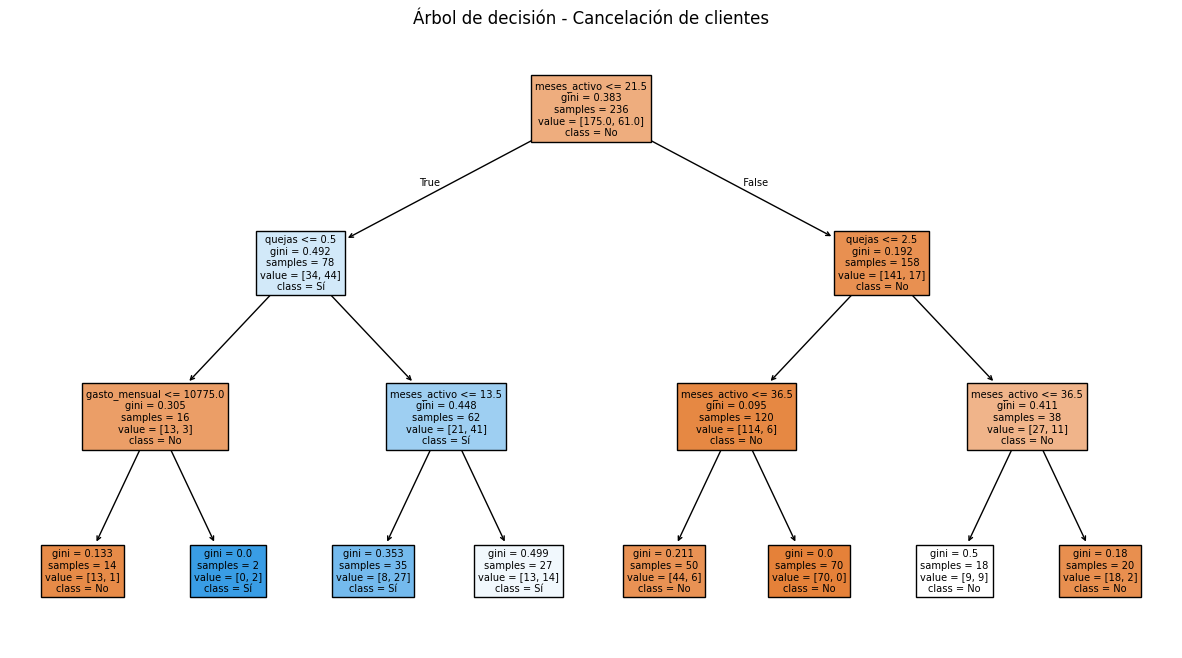

In [24]:
# Dibujamos el árbol de decisión
plt.figure(figsize=(15, 8))

plot_tree(
    modelo,
    feature_names=X.columns,
    class_names=["No", "Sí"],
    filled=True
)

plt.title("Árbol de decisión - Cancelación de clientes")
plt.show()

In [26]:
# Cargamos la hoja de los clientes nuevos
clientes_nuevos = pd.read_excel(nombre_archivo, sheet_name="clientes_nuevos")

# Convertimos el plan a número igual que en los datos de entrenamiento
clientes_nuevos["plan_num"] = clientes_nuevos["plan"].replace({
    "Básico": 0,
    "Estándar": 1,
    "Premium": 2
})

# Seleccionamos las mismas variables que usamos para entrenar
X_nuevos = clientes_nuevos[
    ["edad", "meses_activo", "quejas", "plan_num", "gasto_mensual"]
]

# Hacemos la predicción
clientes_nuevos["prediccion"] = modelo.predict(X_nuevos)

# Mostramos el resultado
display(clientes_nuevos[["id_cliente", "prediccion"]])

/tmp/ipykernel_1440/3668308903.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clientes_nuevos["plan_num"] = clientes_nuevos["plan"].replace({


,id_cliente,prediccion
0,NV-01,Sí
1,NV-02,No
2,NV-03,Sí
3,NV-04,No
4,NV-05,Sí


Conclusión:
El modelo obtuvo una exactitud del 81.67%, por lo que logra identificar correctamente la mayoría de los casos.
Según el árbol de decisión, los meses que lleva activo el cliente y la cantidad de quejas son factores importantes para predecir una cancelación.
Los clientes con menor tiempo en el servicio y ciertas cantidades de quejas presentan mayor posibilidad de cancelar.
Se recomienda a StreamTico dar seguimiento a estos clientes y mejorar la atención de sus quejas para tratar de evitar cancelaciones.